In [1]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
C:\Users\heman\anaconda3\envs\marketing_project\python.exe

Python version:
3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]


In [2]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current folder:
C:\Users\heman\Documents\Capstone_Marketing

Files and folders here:
['.ipynb_checkpoints', 'anaconda_projects', 'Capstone_Marketing_Conversion.ipynb', 'dashboard', 'data', 'models', 'outputs', 'report']


In [3]:
print("Files inside data folder:")
print(os.listdir("data"))

Files inside data folder:
['digital_marketing_campaign_dataset.csv']


# Digital Marketing Campaign Conversion Prediction

**Author:** Hemant Rathod

## Objective

Predict whether a customer will convert after a digital marketing campaign using demographic, marketing and engagement data.

The business goal is to improve campaign targeting, reduce wasted advertising spend and improve return on advertising spend (ROAS).

## Project Approach

This project includes:

- Data loading and validation
- Data cleaning
- SQL business analysis
- Exploratory Data Analysis
- Statistical testing
- Feature engineering
- Machine learning model comparison
- Model evaluation
- Feature importance
- Simple neural network comparison
- AI-assisted business summary
- Power BI dashboard
- Streamlit application
- Deployment
- Final documentation

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

sns.set_style('whitegrid')

%matplotlib inline

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
df = pd.read_csv('data/digital_marketing_campaign_dataset.csv')

print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

df.head()

Rows and columns: (8000, 20)

Column names:
['CustomerID', 'Age', 'Gender', 'Income', 'CampaignChannel', 'CampaignType', 'AdSpend', 'ClickThroughRate', 'ConversionRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints', 'AdvertisingPlatform', 'AdvertisingTool', 'Conversion']


,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1
2,8002,46,Female,88456,PPC,Awareness,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,2,8,2337,IsConfid,ToolConfid,1
3,8003,32,Female,44085,PPC,Conversion,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,2,0,2463,IsConfid,ToolConfid,1
4,8004,60,Female,83964,PPC,Conversion,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,6,8,4345,IsConfid,ToolConfid,1


In [6]:
df.info()

print("\nTotal missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CustomerID           8000 non-null   int64  
 1   Age                  8000 non-null   int64  
 2   Gender               8000 non-null   str    
 3   Income               8000 non-null   int64  
 4   CampaignChannel      8000 non-null   str    
 5   CampaignType         8000 non-null   str    
 6   AdSpend              8000 non-null   float64
 7   ClickThroughRate     8000 non-null   float64
 8   ConversionRate       8000 non-null   float64
 9   WebsiteVisits        8000 non-null   int64  
 10  PagesPerVisit        8000 non-null   float64
 11  TimeOnSite           8000 non-null   float64
 12  SocialShares         8000 non-null   int64  
 13  EmailOpens           8000 non-null   int64  
 14  EmailClicks          8000 non-null   int64  
 15  PreviousPurchases    8000 non-null   int64  
 16 

In [7]:
print("Conversion counts:")
print(df['Conversion'].value_counts())

print("\nConversion percentages:")
print((df['Conversion'].value_counts(normalize=True) * 100).round(2))

print("\nUnique Conversion values:")
print(df['Conversion'].unique())

Conversion counts:
Conversion
1    7012
0     988
Name: count, dtype: int64

Conversion percentages:
Conversion
1    87.65
0    12.35
Name: proportion, dtype: float64

Unique Conversion values:
[1 0]


In [8]:
df_clean = df.copy()

constant_cols = []

for col in df_clean.columns:
    if df_clean[col].nunique() == 1:
        constant_cols.append(col)

print("Columns with only one value:")
print(constant_cols)

drop_cols = ['CustomerID'] + constant_cols

df_clean = df_clean.drop(
    columns=[col for col in drop_cols if col in df_clean.columns]
)

print("\nOriginal shape:", df.shape)
print("Cleaned shape :", df_clean.shape)

Columns with only one value:
['AdvertisingPlatform', 'AdvertisingTool']

Original shape: (8000, 20)
Cleaned shape : (8000, 17)


In [9]:
print("Columns after cleaning:")

for col in df_clean.columns:
    print(col)

Columns after cleaning:
Age
Gender
Income
CampaignChannel
CampaignType
AdSpend
ClickThroughRate
ConversionRate
WebsiteVisits
PagesPerVisit
TimeOnSite
SocialShares
EmailOpens
EmailClicks
PreviousPurchases
LoyaltyPoints
Conversion


In [10]:
missing_values = df_clean.isnull().sum()

print("Missing values:")
print(missing_values[missing_values > 0])

Missing values:
Series([], dtype: int64)


In [11]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


In [12]:
print(df_clean.describe().T[['min', 'max']])

                            min            max
Age                   18.000000      69.000000
Income             20014.000000  149986.000000
AdSpend              100.054813    9997.914781
ClickThroughRate       0.010005       0.299968
ConversionRate         0.010018       0.199995
WebsiteVisits          0.000000      49.000000
PagesPerVisit          1.000428       9.999055
TimeOnSite             0.501669      14.995311
SocialShares           0.000000      99.000000
EmailOpens             0.000000      19.000000
EmailClicks            0.000000       9.000000
PreviousPurchases      0.000000       9.000000
LoyaltyPoints          0.000000    4999.000000
Conversion             0.000000       1.000000


In [13]:
categorical_cols = df_clean.select_dtypes(exclude='number').columns

for col in categorical_cols:
    print("\n", col)
    print(df_clean[col].unique())


 Gender
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

 CampaignChannel
<StringArray>
['Social Media', 'Email', 'PPC', 'Referral', 'SEO']
Length: 5, dtype: str

 CampaignType
<StringArray>
['Awareness', 'Retention', 'Conversion', 'Consideration']
Length: 4, dtype: str


In [14]:
df_clean.to_csv('outputs/cleaned_data.csv', index=False)

print("Cleaned data saved successfully.")

Cleaned data saved successfully.


In [15]:
print("========== CLEANING CHECK ==========")

print("Original data :", df.shape)
print("Cleaned data  :", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicates    :", df_clean.duplicated().sum())
print("CustomerID in data:", 'CustomerID' in df_clean.columns)

print("====================================")

========== CLEANING CHECK ==========
Original data : (8000, 20)
Cleaned data  : (8000, 17)
Missing values: 0
Duplicates    : 0
CustomerID in data: False


## Data Cleaning Observations

The original dataset contained 8,000 rows and 20 columns.

I removed `CustomerID` because it is an identifier and does not represent a useful customer characteristic.

I also removed `AdvertisingPlatform` and `AdvertisingTool` because they contained only one unique value and therefore did not provide useful variation for analysis or prediction.

There were no missing values or duplicate rows, so no rows were removed and no missing-value imputation was required.

The cleaned dataset contains 8,000 rows and 17 columns.

# Stage 5 — Exploratory Data Analysis: Distributions


Numeric features: ['Age', 'Income', 'AdSpend', 'ClickThroughRate', 'ConversionRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints']
Categorical features: ['Gender', 'CampaignChannel', 'CampaignType']


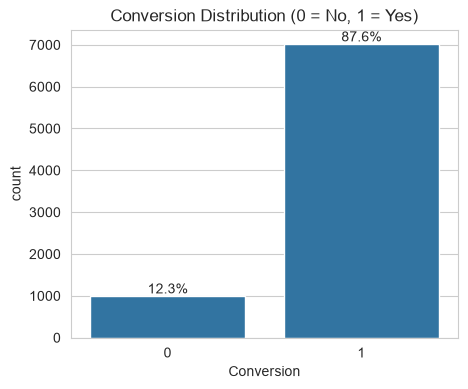

In [16]:
# Identify numeric and categorical features
num_cols = df_clean.select_dtypes(include='number').columns.drop('Conversion').tolist()
cat_cols = df_clean.select_dtypes(exclude='number').columns.tolist()

print('Numeric features:', num_cols)
print('Categorical features:', cat_cols)

# Check the distribution of the target variable
fig, ax = plt.subplots(figsize=(5, 4))

sns.countplot(x='Conversion', data=df_clean, ax=ax)

for p in ax.patches:
    share = p.get_height() / len(df_clean) * 100
    ax.annotate(
        f'{share:.1f}%',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom'
    )

ax.set_title('Conversion Distribution (0 = No, 1 = Yes)')

plt.savefig(
    'outputs/fig01_target.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

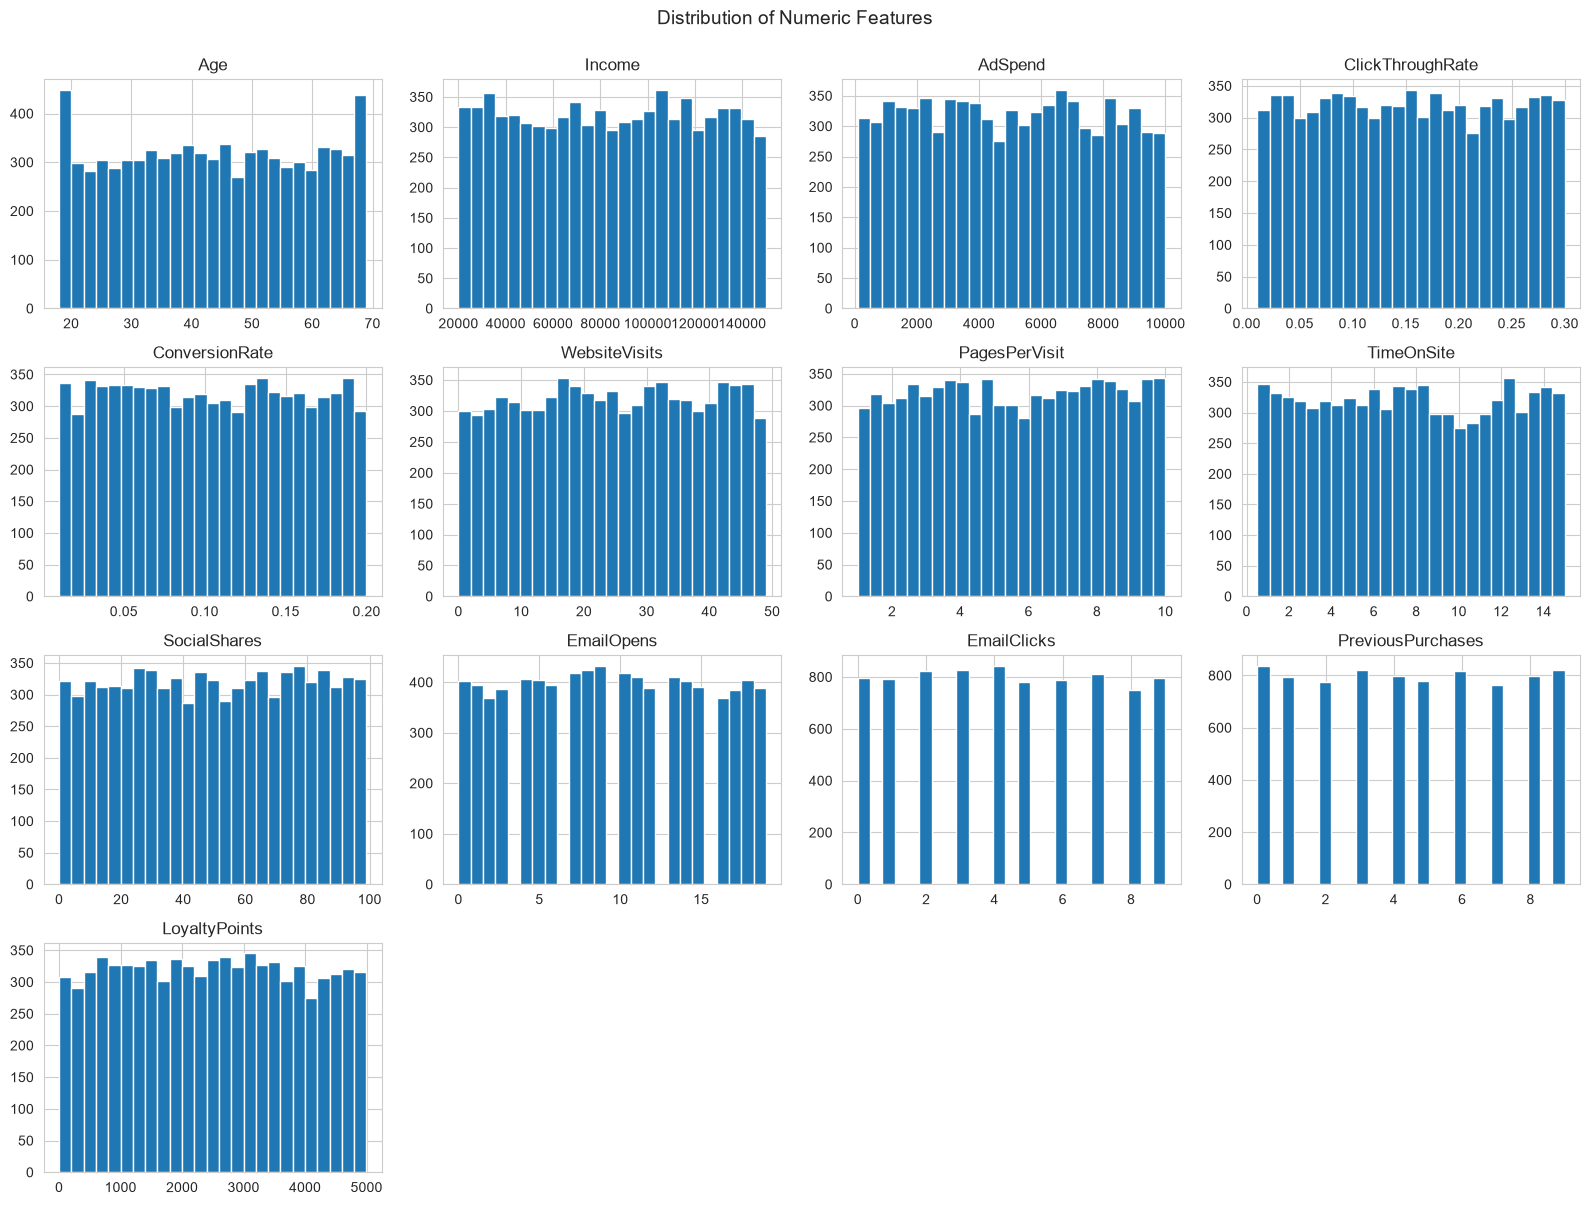

Age                 -0.00
Income              -0.01
AdSpend              0.02
ClickThroughRate     0.01
ConversionRate       0.01
WebsiteVisits       -0.02
PagesPerVisit       -0.01
TimeOnSite           0.01
SocialShares        -0.01
EmailOpens           0.01
EmailClicks          0.02
PreviousPurchases    0.01
LoyaltyPoints        0.02
dtype: float64

In [17]:
# Look at the distribution of all numeric features
df_clean[num_cols].hist(
    bins=25,
    figsize=(16, 12)
)

plt.suptitle(
    'Distribution of Numeric Features',
    y=1.0,
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    'outputs/fig02_numeric_distributions.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

# Check how skewed each numeric feature is
df_clean[num_cols].skew().round(2)

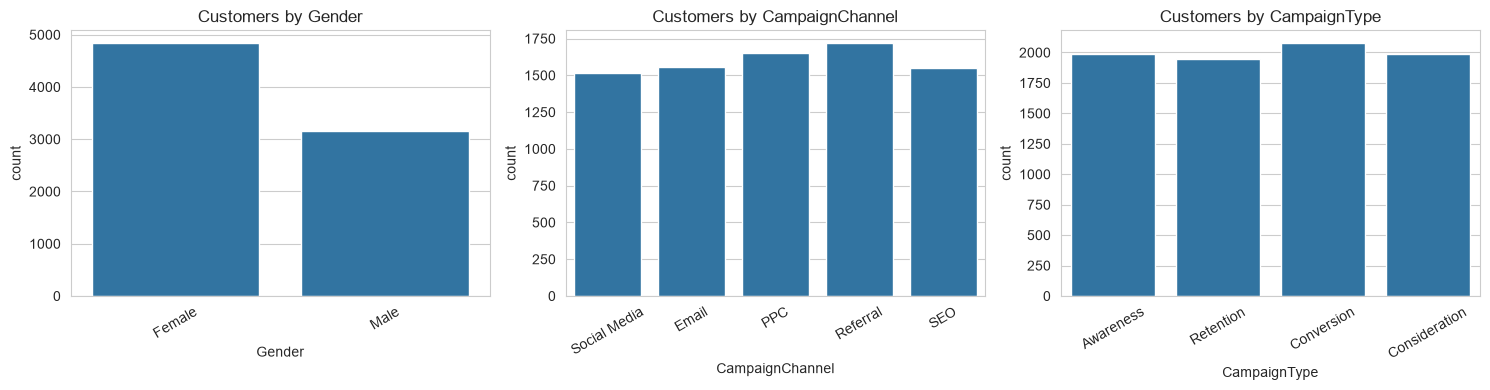

In [18]:
# Compare the number of customers in each category
fig, axes = plt.subplots(
    1,
    len(cat_cols),
    figsize=(5 * len(cat_cols), 4)
)

for ax, c in zip(np.atleast_1d(axes), cat_cols):
    sns.countplot(x=c, data=df_clean, ax=ax)
    ax.set_title('Customers by ' + c)
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()

plt.savefig(
    'outputs/fig03_categorical_counts.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

# Stage 6 — Relationships and Correlations

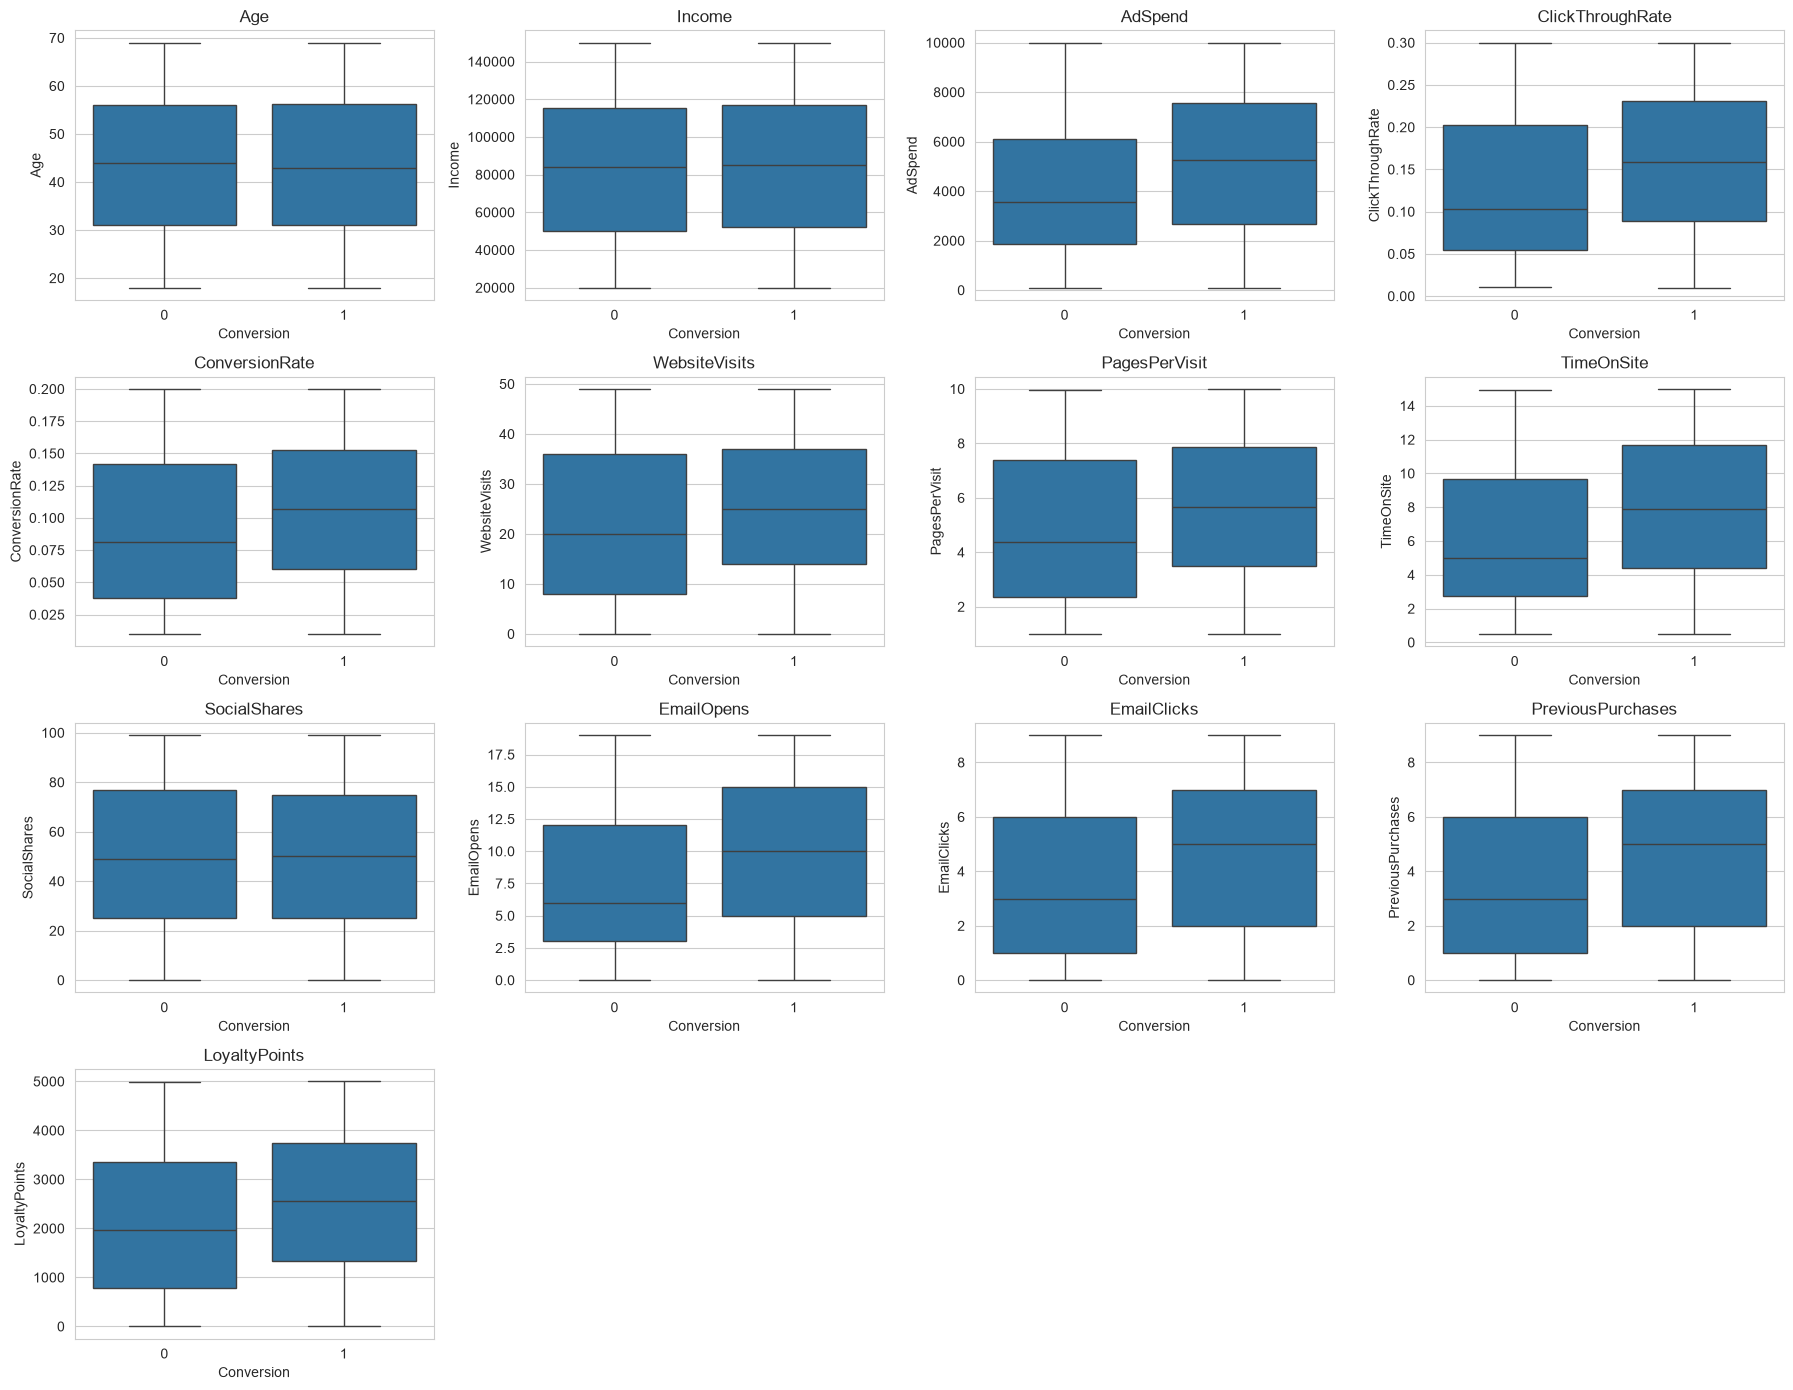

Conversion,0,1
Age,43.56,43.63
Income,83265.31,84861.30
AdSpend,4058.40,5133.75
ClickThroughRate,0.13,0.16
ConversionRate,0.09,0.11
WebsiteVisits,21.73,25.18
PagesPerVisit,4.84,5.65
TimeOnSite,6.27,7.93
SocialShares,50.68,49.68
EmailOpens,7.58,9.74


In [19]:
# Compare numeric features between customers who converted and did not convert

fig, axes = plt.subplots(4, 4, figsize=(18, 14))

flat = axes.flatten()

for ax, c in zip(flat, num_cols):
    sns.boxplot(
        x='Conversion',
        y=c,
        data=df_clean,
        ax=ax
    )
    ax.set_title(c)

# Hide unused chart spaces
for ax in flat[len(num_cols):]:
    ax.axis('off')

plt.tight_layout()

plt.savefig(
    'outputs/fig04_boxplots_by_conversion.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

# Show average values for converted and non-converted customers
df_clean.groupby('Conversion')[num_cols].mean().T.round(2)

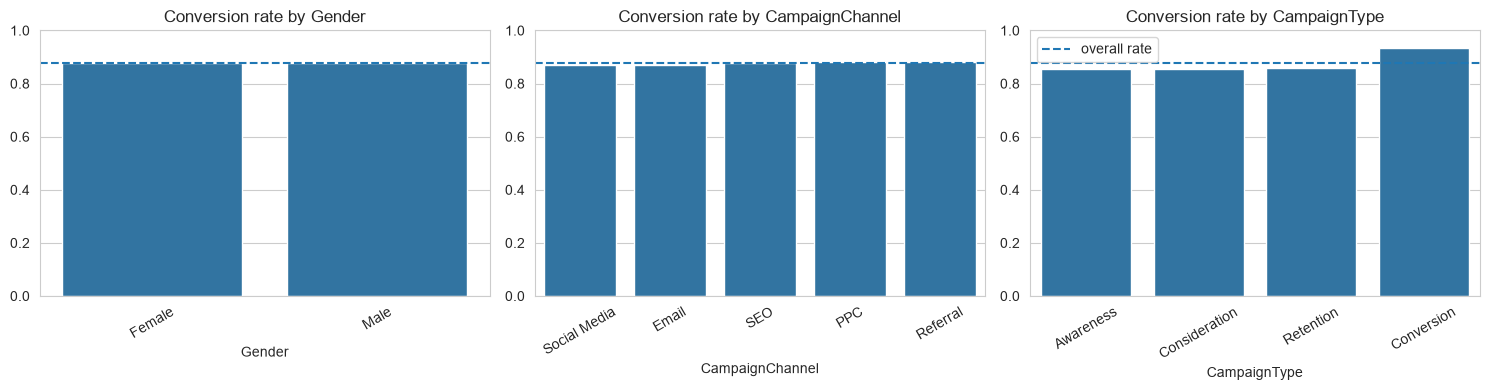

In [20]:
# Compare conversion rates across categorical features

overall = df_clean['Conversion'].mean()

fig, axes = plt.subplots(
    1,
    len(cat_cols),
    figsize=(5 * len(cat_cols), 4)
)

for ax, c in zip(np.atleast_1d(axes), cat_cols):

    rate = (
        df_clean
        .groupby(c)['Conversion']
        .mean()
        .sort_values()
    )

    sns.barplot(
        x=rate.index,
        y=rate.values,
        ax=ax
    )

    ax.axhline(
        overall,
        linestyle='--',
        label='overall rate'
    )

    ax.set_title('Conversion rate by ' + c)
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=30)

ax.legend()

plt.tight_layout()

plt.savefig(
    'outputs/fig05_conversion_rate_by_category.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

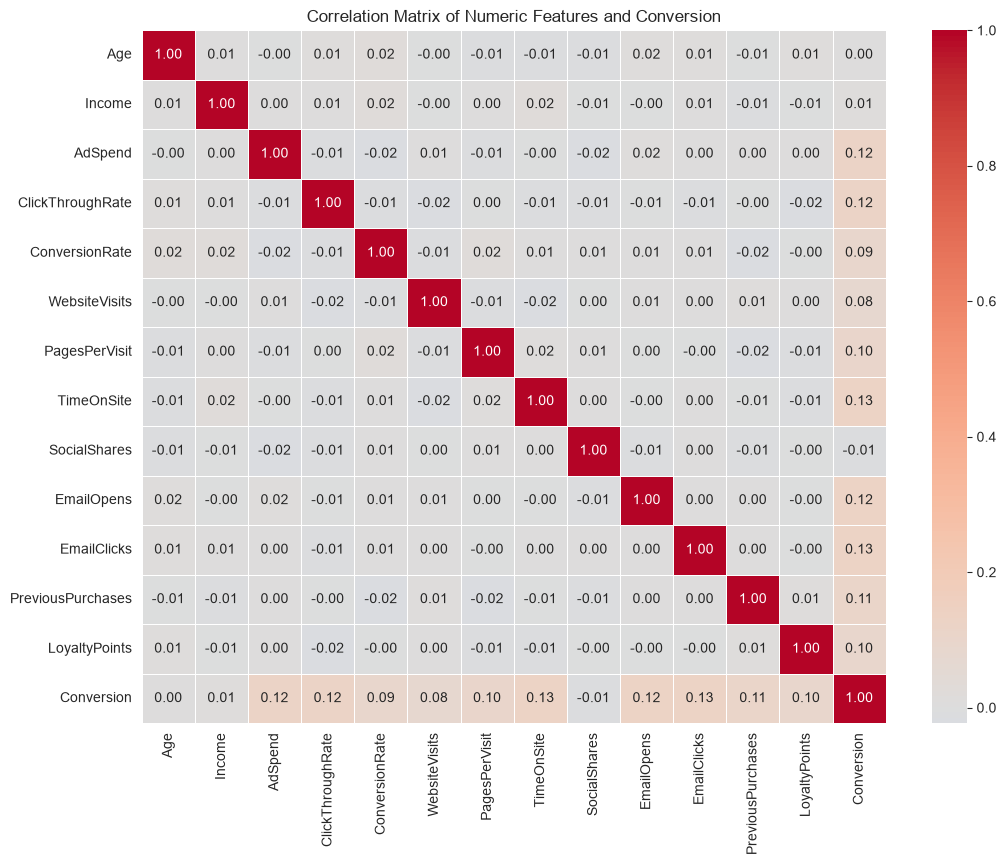

In [21]:
# Check correlations between numeric features and the target

plt.figure(figsize=(12, 9))

sns.heatmap(
    df_clean[num_cols + ['Conversion']].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title(
    'Correlation Matrix of Numeric Features and Conversion'
)

plt.savefig(
    'outputs/fig06_correlation_heatmap.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

In [22]:
# Find which numeric features have the strongest correlation with Conversion

corr_with_target = (
    df_clean[num_cols + ['Conversion']]
    .corr()['Conversion']
    .drop('Conversion')
    .sort_values(
        key=abs,
        ascending=False
    )
)

corr_with_target.round(3)

TimeOnSite           0.130
EmailClicks          0.130
EmailOpens           0.125
AdSpend              0.125
ClickThroughRate     0.120
PreviousPurchases    0.112
PagesPerVisit        0.103
LoyaltyPoints        0.095
ConversionRate       0.093
WebsiteVisits        0.079
Income               0.014
SocialShares        -0.011
Age                  0.002
Name: Conversion, dtype: float64

# Stage 7 — Statistical Tests

In [23]:
from scipy import stats

rows = []

for c in num_cols:
    converted = df_clean.loc[df_clean['Conversion'] == 1, c]
    not_converted = df_clean.loc[df_clean['Conversion'] == 0, c]

    stat, p = stats.mannwhitneyu(
        converted,
        not_converted,
        alternative='two-sided'
    )

    rows.append([
        c,
        round(converted.mean(), 3),
        round(not_converted.mean(), 3),
        p
    ])

num_tests = pd.DataFrame(
    rows,
    columns=[
        'Feature',
        'Mean converted',
        'Mean not converted',
        'p-value'
    ]
)

num_tests['Significant (p<0.05)'] = (
    num_tests['p-value'] < 0.05
)

num_tests.sort_values('p-value')

,Feature,Mean converted,Mean not converted,p-value,Significant (p<0.05)
10,EmailClicks,4.606,3.482,2.682680e-31,True
7,TimeOnSite,7.933,6.268,3.571616e-31,True
9,EmailOpens,9.745,7.577,4.943998e-29,True
2,AdSpend,5133.751,4058.398,8.253685e-29,True
3,ClickThroughRate,0.159,0.128,4.959782e-27,True
11,PreviousPurchases,4.607,3.626,1.452119e-23,True
6,PagesPerVisit,5.650,4.835,3.417654e-20,True
12,LoyaltyPoints,2541.244,2128.484,1.564602e-17,True
4,ConversionRate,0.106,0.091,4.786608e-17,True
5,WebsiteVisits,25.178,21.727,2.059745e-12,True


In [24]:
rows = []

for c in cat_cols:
    table = pd.crosstab(
        df_clean[c],
        df_clean['Conversion']
    )

    chi2, p, dof, expected = stats.chi2_contingency(table)

    rows.append([
        c,
        round(chi2, 2),
        p
    ])

cat_tests = pd.DataFrame(
    rows,
    columns=[
        'Feature',
        'Chi-square',
        'p-value'
    ]
)

cat_tests['Significant (p<0.05)'] = (
    cat_tests['p-value'] < 0.05
)

cat_tests

,Feature,Chi-square,p-value,Significant (p<0.05)
0,Gender,0.00,9.510312e-01,False
1,CampaignChannel,2.78,5.944500e-01,False
2,CampaignType,84.45,3.398335e-18,True


In [25]:
all_tests = pd.concat([
    num_tests[
        ['Feature', 'p-value', 'Significant (p<0.05)']
    ].assign(Test='Mann-Whitney U'),

    cat_tests[
        ['Feature', 'p-value', 'Significant (p<0.05)']
    ].assign(Test='Chi-square')
])

all_tests = all_tests.sort_values('p-value')

all_tests

,Feature,p-value,Significant (p<0.05),Test
10,EmailClicks,2.682680e-31,True,Mann-Whitney U
7,TimeOnSite,3.571616e-31,True,Mann-Whitney U
9,EmailOpens,4.943998e-29,True,Mann-Whitney U
2,AdSpend,8.253685e-29,True,Mann-Whitney U
3,ClickThroughRate,4.959782e-27,True,Mann-Whitney U
11,PreviousPurchases,1.452119e-23,True,Mann-Whitney U
6,PagesPerVisit,3.417654e-20,True,Mann-Whitney U
2,CampaignType,3.398335e-18,True,Chi-square
12,LoyaltyPoints,1.564602e-17,True,Mann-Whitney U
4,ConversionRate,4.786608e-17,True,Mann-Whitney U


In [26]:
all_tests.to_csv(
    'outputs/statistical_tests.csv',
    index=False
)

print('Statistical test results saved successfully.')

Statistical test results saved successfully.


In [27]:
print('Number of numeric tests:', len(num_tests))
print('Number of categorical tests:', len(cat_tests))
print('Total tests:', len(all_tests))

Number of numeric tests: 13
Number of categorical tests: 3
Total tests: 16


### My observation

The Mann–Whitney U test showed statistically significant differences between converted and non-converted customers for 10 of the 13 numeric features. EmailClicks, TimeOnSite, EmailOpens, AdSpend and ClickThroughRate had some of the smallest p-values, while Income, SocialShares and Age were not statistically significant.

For the categorical variables, CampaignType was statistically significant, while Gender and CampaignChannel were not.

A p-value below 0.05 was treated as statistically significant. However, statistical significance does not necessarily mean that a feature is practically important or that it causes conversion. With 8,000 observations, even relatively small differences can become statistically significant.

# Stage 8 — Feature Engineering

In [28]:
# Create a separate dataframe for feature engineering
df_fe = df_clean.copy()

# Email clicks compared with email opens
df_fe['EmailClickRate'] = (
    df_fe['EmailClicks'] / (df_fe['EmailOpens'] + 1)
)

# Advertising spend compared with website visits
df_fe['SpendPerVisit'] = (
    df_fe['AdSpend'] / (df_fe['WebsiteVisits'] + 1)
)

print(
    'Missing values after adding features:',
    df_fe.isnull().sum().sum()
)

df_fe[
    ['EmailClickRate', 'SpendPerVisit']
].describe().T.round(3)

Missing values after adding features: 0


,count,mean,std,min,25%,50%,75%,max
EmailClickRate,8000.0,0.793,1.224,0.000,0.200,0.429,0.818,9.000
SpendPerVisit,8000.0,430.369,900.368,2.532,99.382,194.866,370.408,9853.176


In [29]:
# Compare the new features for non-converters and converters
df_fe.groupby(
    'Conversion'
)[
    ['EmailClickRate', 'SpendPerVisit']
].mean().round(3)

,EmailClickRate,SpendPerVisit
Conversion,,
0,0.811,461.672
1,0.790,425.958


In [30]:
print('Original columns:', df_clean.shape[1])
print('New dataframe columns:', df_fe.shape[1])
print('New features:', df_fe.shape[1] - df_clean.shape[1])

Original columns: 17
New dataframe columns: 19
New features: 2


# Stage 9 — Preprocessing for Machine Learning

In this stage, I prepare the dataset for machine learning by separating the target variable, splitting the data into training and testing sets, encoding categorical variables, and scaling numerical variables.

In [31]:
from sklearn.model_selection import train_test_split

X = df_fe.drop(columns='Conversion')
y = df_clean['Conversion']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print('Training rows:', X_train.shape[0])
print('Test rows:', X_test.shape[0])
print('Converted share train:', round(y_train.mean(), 3))
print('Converted share test:', round(y_test.mean(), 3))

Training rows: 6400
Test rows: 1600
Converted share train: 0.877
Converted share test: 0.876


### My observation

I split the dataset into 80% training data and 20% testing data. Stratification was used so that the proportion of converted customers remains approximately the same in both datasets.

In [32]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

num_features = X.select_dtypes(include='number').columns.tolist()
cat_features = X.select_dtypes(exclude='number').columns.tolist()

preprocess = ColumnTransformer([
    ('scale', StandardScaler(), num_features),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

print('Numeric features to scale:', len(num_features))
print('Numeric feature names:', num_features)
print('Categorical features to encode:', cat_features)

Numeric features to scale: 15
Numeric feature names: ['Age', 'Income', 'AdSpend', 'ClickThroughRate', 'ConversionRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints', 'EmailClickRate', 'SpendPerVisit']
Categorical features to encode: ['Gender', 'CampaignChannel', 'CampaignType']


In [33]:
Xt = preprocess.fit_transform(X_train)

feature_names = preprocess.get_feature_names_out()

print('Columns before:', X_train.shape[1])
print('Columns after encoding:', Xt.shape[1])

pd.DataFrame(
    Xt[:3],
    columns=feature_names
).round(2)

Columns before: 18
Columns after encoding: 26


,scale__Age,scale__Income,scale__AdSpend,scale__ClickThroughRate,scale__ConversionRate,scale__WebsiteVisits,scale__PagesPerVisit,scale__TimeOnSite,scale__SocialShares,scale__EmailOpens,scale__EmailClicks,scale__PreviousPurchases,scale__LoyaltyPoints,scale__EmailClickRate,scale__SpendPerVisit,encode__Gender_Female,encode__Gender_Male,encode__CampaignChannel_Email,encode__CampaignChannel_PPC,encode__CampaignChannel_Referral,encode__CampaignChannel_SEO,encode__CampaignChannel_Social Media,encode__CampaignType_Awareness,encode__CampaignType_Consideration,encode__CampaignType_Conversion,encode__CampaignType_Retention
0,-1.19,1.26,0.90,1.58,0.44,0.71,-0.48,1.10,-0.27,1.32,-1.56,0.18,-0.86,-0.65,-0.25,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.63,-0.54,0.22,-1.55,-0.53,1.07,1.33,1.21,0.67,-0.60,-1.56,-0.17,0.81,-0.65,-0.33,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,0.83,0.94,-1.66,-1.58,0.95,1.42,0.59,-0.51,-1.03,1.15,-0.16,0.52,1.71,-0.46,-0.47,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


### My observation

The preprocessing step increased the number of model input columns because categorical variables were converted into separate one-hot encoded columns. Numerical variables were scaled so that variables with different units and ranges can be handled more appropriately by scale-sensitive models.

In [35]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

print("Machine learning models imported successfully.")

Machine learning models imported successfully.


In [36]:
from xgboost import XGBClassifier

print("XGBoost imported successfully.")

XGBoost imported successfully.


In [37]:
models = {
    "Dummy Classifier": DummyClassifier(strategy="most_frequent"),
    
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    
    "Naive Bayes": GaussianNB(),
    
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        max_depth=8
    ),
    
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE,
        n_estimators=100
    ),
    
    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        random_state=RANDOM_STATE,
        eval_metric="logloss"
    )
}

print("Number of models:", len(models))
print("Models:")
for name in models:
    print("-", name)

Number of models: 8
Models:
- Dummy Classifier
- Logistic Regression
- KNN
- Naive Bayes
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost


In [38]:
from sklearn.pipeline import Pipeline

pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline([
        ("preprocess", preprocess),
        ("model", model)
    ])

print("Model pipelines created:", len(pipelines))

Model pipelines created: 8


In [39]:
trained_models = {}

for name, pipeline in pipelines.items():
    print("Training:", name)
    
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

print("\nAll models trained successfully.")

Training: Dummy Classifier
Training: Logistic Regression
Training: KNN
Training: Naive Bayes
Training: Decision Tree
Training: Random Forest
Training: Gradient Boosting
Training: XGBoost

All models trained successfully.


In [40]:
predictions = {}
probabilities = {}

for name, model in trained_models.items():
    predictions[name] = model.predict(X_test)
    
    if hasattr(model, "predict_proba"):
        probabilities[name] = model.predict_proba(X_test)[:, 1]

print("Predictions generated for:", len(predictions), "models")

Predictions generated for: 8 models


In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name in trained_models:
    y_pred = predictions[name]
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    if name in probabilities:
        roc_auc = roc_auc_score(y_test, probabilities[name])
    else:
        roc_auc = None
    
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

model_results = pd.DataFrame(results)

model_results = model_results.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

model_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.9175,0.9205,0.9914,0.9547,0.8204
1,Gradient Boosting,0.9119,0.9140,0.9929,0.9518,0.8144
2,Random Forest,0.8906,0.8915,0.9964,0.9411,0.8125
3,Logistic Regression,0.8900,0.8935,0.9929,0.9405,0.7857
4,Naive Bayes,0.8894,0.8924,0.9936,0.9403,0.7872
5,KNN,0.8781,0.8837,0.9914,0.9345,0.6514
6,Dummy Classifier,0.8762,0.8762,1.0000,0.9340,0.5000
7,Decision Tree,0.8706,0.9051,0.9522,0.9281,0.6828


In [42]:
model_results.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")
print("File: outputs/model_comparison.csv")

Model comparison saved successfully.
File: outputs/model_comparison.csv


### My observation

I trained and compared multiple classification algorithms for predicting customer conversion. I used a dummy classifier as a baseline and then tested linear, distance-based, probabilistic, tree-based and boosting algorithms.

The models were evaluated using accuracy, precision, recall, F1 score and ROC-AUC. I will select the final model based on overall predictive performance rather than accuracy alone, because the conversion dataset contains class imbalance.

In [43]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

for name in trained_models:
    cm = confusion_matrix(y_test, predictions[name])
    
    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)
    print("Confusion Matrix:")
    print(cm)


Dummy Classifier
Confusion Matrix:
[[   0  198]
 [   0 1402]]

Logistic Regression
Confusion Matrix:
[[  32  166]
 [  10 1392]]

KNN
Confusion Matrix:
[[  15  183]
 [  12 1390]]

Naive Bayes
Confusion Matrix:
[[  30  168]
 [   9 1393]]

Decision Tree
Confusion Matrix:
[[  58  140]
 [  67 1335]]

Random Forest
Confusion Matrix:
[[  28  170]
 [   5 1397]]

Gradient Boosting
Confusion Matrix:
[[  67  131]
 [  10 1392]]

XGBoost
Confusion Matrix:
[[  78  120]
 [  12 1390]]


In [44]:
from sklearn.metrics import classification_report

xgb_predictions = predictions["XGBoost"]

print("XGBoost Classification Report")
print("=" * 50)

print(
    classification_report(
        y_test,
        xgb_predictions,
        target_names=["Not Converted", "Converted"],
        digits=4
    )
)

XGBoost Classification Report
               precision    recall  f1-score   support

Not Converted     0.8667    0.3939    0.5417       198
    Converted     0.9205    0.9914    0.9547      1402

     accuracy                         0.9175      1600
    macro avg     0.8936    0.6927    0.7482      1600
 weighted avg     0.9139    0.9175    0.9036      1600



<Figure size 600x500 with 0 Axes>

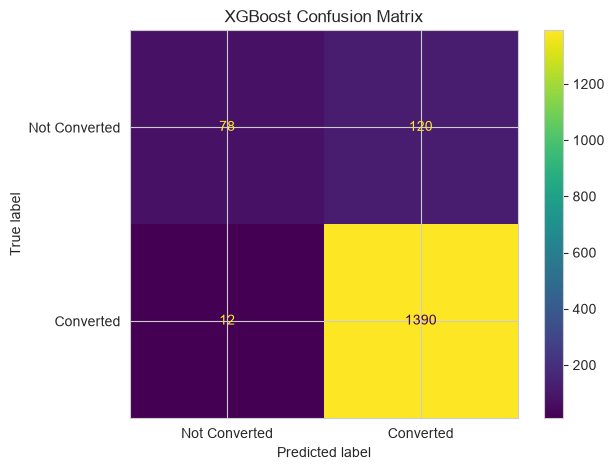

In [45]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_predictions,
    display_labels=["Not Converted", "Converted"],
    values_format="d"
)

plt.title("XGBoost Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "outputs/fig07_xgboost_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

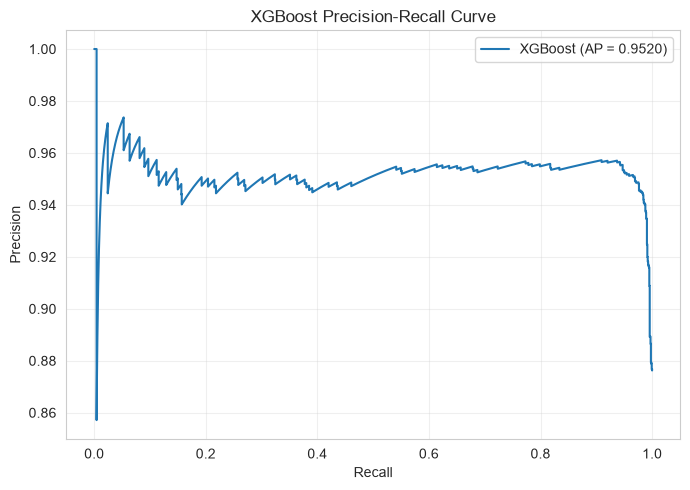

Average Precision: 0.952


In [46]:
from sklearn.metrics import precision_recall_curve, average_precision_score

xgb_probabilities = probabilities["XGBoost"]

precision, recall, thresholds = precision_recall_curve(
    y_test,
    xgb_probabilities
)

average_precision = average_precision_score(
    y_test,
    xgb_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f"XGBoost (AP = {average_precision:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("XGBoost Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "outputs/fig08_xgboost_precision_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Average Precision:", round(average_precision, 4))

In [47]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for name, pipeline in pipelines.items():
    
    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=1
    )
    
    cv_results.append({
        "Model": name,
        "CV F1 macro": scores.mean(),
        "CV F1 std": scores.std()
    })

cv_results = pd.DataFrame(cv_results)

cv_results = cv_results.sort_values(
    by="CV F1 macro",
    ascending=False
).reset_index(drop=True)

cv_results.round(4)

,Model,CV F1 macro,CV F1 std
0,XGBoost,0.7503,0.0196
1,Gradient Boosting,0.7338,0.0172
2,Decision Tree,0.6417,0.0229
3,Logistic Regression,0.6232,0.0195
4,Naive Bayes,0.6071,0.0255
5,Random Forest,0.5959,0.0227
6,KNN,0.5354,0.0132
7,Dummy Classifier,0.4671,0.0000


In [48]:
from sklearn.model_selection import GridSearchCV

best_name = cv_results.loc[0, "Model"]
best_cv = cv_results.loc[0, "CV F1 macro"]

print("Best model by cross-validation F1 macro:", best_name)
print("CV F1 macro before tuning:", round(best_cv, 4))

param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [3, 5]
}

grid = GridSearchCV(
    pipelines[best_name],
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1
)

grid.fit(X_train, y_train)

print("\nBest settings found:")
print(grid.best_params_)

print(
    "CV F1 macro after tuning:",
    round(grid.best_score_, 4)
)

print(
    "CV F1 macro before tuning:",
    round(best_cv, 4)
)

if grid.best_score_ >= best_cv:
    final_model = grid.best_estimator_
    print("\nUsing the tuned model.")
else:
    final_model = pipelines[best_name]
    print("\nTuning did not improve the score. Keeping the default model.")

Best model by cross-validation F1 macro: XGBoost
CV F1 macro before tuning: 0.7503

Best settings found:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
CV F1 macro after tuning: 0.7695
CV F1 macro before tuning: 0.7503

Using the tuned model.


In [49]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Predict classes
y_test_pred = final_model.predict(X_test)

# Predict probabilities
y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Calculate final metrics
final_accuracy = accuracy_score(y_test, y_test_pred)
final_precision = precision_score(y_test, y_test_pred)
final_recall = recall_score(y_test, y_test_pred)
final_f1 = f1_score(y_test, y_test_pred)
final_f1_macro = f1_score(y_test, y_test_pred, average="macro")
final_roc_auc = roc_auc_score(y_test, y_test_prob)
final_average_precision = average_precision_score(y_test, y_test_prob)

print("FINAL TEST SET RESULTS")
print("=" * 60)

print("Accuracy:", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall:", round(final_recall, 4))
print("F1 Score:", round(final_f1, 4))
print("F1 Macro:", round(final_f1_macro, 4))
print("ROC-AUC:", round(final_roc_auc, 4))
print("Average Precision:", round(final_average_precision, 4))

print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Not Converted", "Converted"]
    )
)

print("\nCONFUSION MATRIX")
print("=" * 60)

print(confusion_matrix(y_test, y_test_pred))

FINAL TEST SET RESULTS
Accuracy: 0.9219
Precision: 0.9237
Recall: 0.9929
F1 Score: 0.957
F1 Macro: 0.7637
ROC-AUC: 0.8171
Average Precision: 0.9494

CLASSIFICATION REPORT
               precision    recall  f1-score   support

Not Converted       0.89      0.42      0.57       198
    Converted       0.92      0.99      0.96      1402

     accuracy                           0.92      1600
    macro avg       0.91      0.71      0.76      1600
 weighted avg       0.92      0.92      0.91      1600


CONFUSION MATRIX
[[  83  115]
 [  10 1392]]


In [50]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "F1 Macro",
        "ROC-AUC",
        "Average Precision"
    ],
    "Score": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        final_f1_macro,
        final_roc_auc,
        final_average_precision
    ]
})

final_metrics["Score"] = final_metrics["Score"].round(4)

final_metrics.to_csv(
    "outputs/final_model_metrics.csv",
    index=False
)

print("Final model metrics saved successfully.")
print("\nFile:")
print("outputs/final_model_metrics.csv")

print("\nFinal metrics:")
print(final_metrics)

Final model metrics saved successfully.

File:
outputs/final_model_metrics.csv

Final metrics:
              Metric   Score
0           Accuracy  0.9219
1          Precision  0.9237
2             Recall  0.9929
3           F1 Score  0.9570
4           F1 Macro  0.7637
5            ROC-AUC  0.8171
6  Average Precision  0.9494


<Figure size 600x500 with 0 Axes>

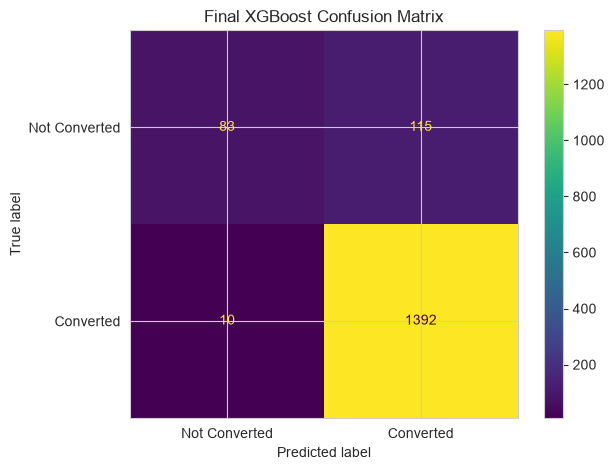

Confusion matrix saved successfully.
File: outputs/fig09_final_confusion_matrix.png


In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Converted", "Converted"]
)

disp.plot()

plt.title("Final XGBoost Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "outputs/fig09_final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully.")
print("File: outputs/fig09_final_confusion_matrix.png")

In [52]:
# Get feature names after preprocessing
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance from the XGBoost model
xgb_model = final_model.named_steps["model"]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("TOP 15 FEATURES")
print("=" * 60)

print(
    feature_importance.head(15).round(4)
)

KeyError: 'preprocessor'

In [54]:
print("========================================")
print("FINAL MODEL STEP NAMES")
print("========================================")

print(final_model.named_steps.keys())

FINAL MODEL STEP NAMES
dict_keys(['preprocess', 'model'])


In [55]:
# Get the preprocessing step
preprocess = final_model.named_steps["preprocess"]

# Get the XGBoost model
xgb_model = final_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = preprocess.get_feature_names_out()

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("TOP 15 FEATURES")
print("=" * 60)

print(feature_importance.head(15).round(4))

TOP 15 FEATURES
                            Feature  Importance
0          scale__PreviousPurchases      0.0946
1                scale__EmailClicks      0.0794
2   encode__CampaignType_Conversion      0.0742
3                 scale__EmailOpens      0.0684
4                 scale__TimeOnSite      0.0678
5              scale__PagesPerVisit      0.0646
6              scale__WebsiteVisits      0.0614
7             scale__ConversionRate      0.0607
8           scale__ClickThroughRate      0.0573
9                    scale__AdSpend      0.0553
10             scale__LoyaltyPoints      0.0522
11            scale__EmailClickRate      0.0285
12   encode__CampaignType_Retention      0.0234
13    encode__CampaignChannel_Email      0.0224
14              scale__SocialShares      0.0213


In [56]:
# Get the preprocessing and XGBoost steps
preprocess = final_model.named_steps["preprocess"]
xgb_model = final_model.named_steps["model"]

# Get transformed feature names
transformed_names = preprocess.get_feature_names_out()

# Get model importance values
importance_values = xgb_model.feature_importances_

# Remove preprocessing prefixes
clean_names = [
    name.split("__", 1)[1]
    for name in transformed_names
]

# Create initial importance table
imp = pd.DataFrame({
    "feature": clean_names,
    "importance": importance_values
})

# Convert one-hot encoded categorical features
# back to their original feature names
def original_name(feature):
    for c in cat_features:
        if feature.startswith(c + "_"):
            return c
    return feature

imp["Feature"] = imp["feature"].apply(original_name)

# Combine importance belonging to the same original feature
imp_grouped = (
    imp.groupby("Feature")["importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
    .rename(columns={"importance": "Importance"})
)

imp_grouped["Importance"] = imp_grouped["Importance"].round(4)

# Save the final feature importance table
imp_grouped.to_csv(
    "outputs/feature_importance.csv",
    index=False
)

print("FINAL FEATURE IMPORTANCE")
print("=" * 60)

print(imp_grouped)

print("\nTotal importance:", round(imp_grouped["Importance"].sum(), 4))
print("Number of original features:", len(imp_grouped))

FINAL FEATURE IMPORTANCE
              Feature  Importance
0        CampaignType      0.1306
1   PreviousPurchases      0.0946
2     CampaignChannel      0.0830
3         EmailClicks      0.0794
4          EmailOpens      0.0684
5          TimeOnSite      0.0678
6       PagesPerVisit      0.0646
7       WebsiteVisits      0.0614
8      ConversionRate      0.0607
9    ClickThroughRate      0.0573
10            AdSpend      0.0553
11      LoyaltyPoints      0.0522
12     EmailClickRate      0.0285
13       SocialShares      0.0213
14             Gender      0.0206
15             Income      0.0187
16                Age      0.0182
17      SpendPerVisit      0.0173

Total importance: 0.9999
Number of original features: 18


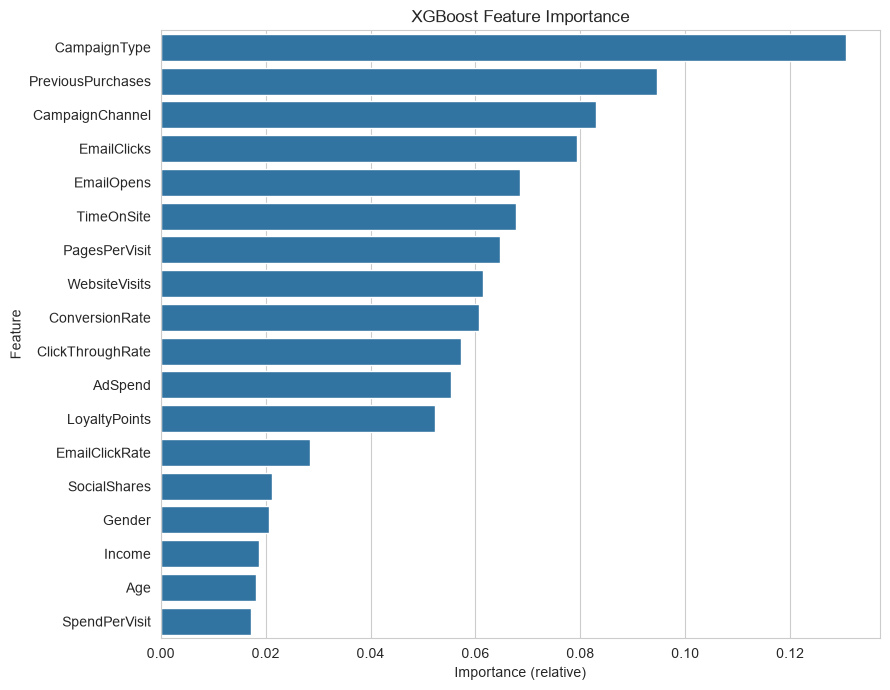

Feature importance chart saved successfully.
File: outputs/fig10_feature_importance.png

Top 5 model features:
['CampaignType', 'PreviousPurchases', 'CampaignChannel', 'EmailClicks', 'EmailOpens']

Top 5 correlation features from EDA:
['TimeOnSite', 'EmailClicks', 'EmailOpens', 'AdSpend', 'ClickThroughRate']


In [57]:
plt.figure(figsize=(9, 7))

sns.barplot(
    x="Importance",
    y="Feature",
    data=imp_grouped
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance (relative)")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    "outputs/fig10_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance chart saved successfully.")
print("File: outputs/fig10_feature_importance.png")

print("\nTop 5 model features:")
print(imp_grouped["Feature"].head(5).tolist())

print("\nTop 5 correlation features from EDA:")
print(corr_with_target.head(5).index.tolist())

Features shown: ['PreviousPurchases', 'EmailClicks']


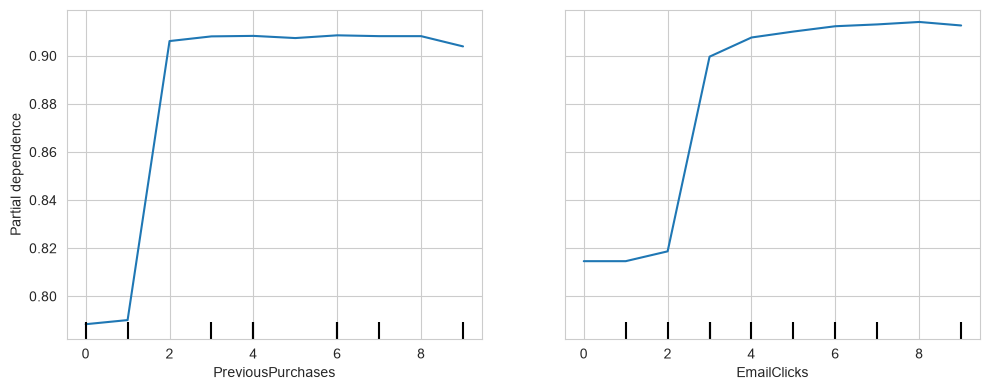

Partial dependence plot saved successfully.
File: outputs/fig11_partial_dependence.png


In [59]:
from sklearn.inspection import PartialDependenceDisplay

# Select the first two important numeric features
top_numeric = [
    f for f in imp_grouped["Feature"]
    if f in num_features
][:2]

print("Features shown:", top_numeric)

# Create a copy only for the partial dependence calculation
X_test_pdp = X_test.copy()

# Convert selected numeric features from integer to float
for feature in top_numeric:
    X_test_pdp[feature] = X_test_pdp[feature].astype(float)

# Create partial dependence plots
display = PartialDependenceDisplay.from_estimator(
    final_model,
    X_test_pdp,
    top_numeric
)

display.figure_.set_size_inches(10, 4)

display.figure_.tight_layout()

display.figure_.savefig(
    "outputs/fig11_partial_dependence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Partial dependence plot saved successfully.")
print("File: outputs/fig11_partial_dependence.png")

In [60]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

# Build a small neural network pipeline
mlp = Pipeline([
    (
        "preprocess",
        preprocess
    ),
    (
        "model",
        MLPClassifier(
            hidden_layer_sizes=(32, 16),
            early_stopping=True,
            max_iter=300,
            random_state=RANDOM_STATE
        )
    )
])

# Train the neural network
mlp.fit(X_train, y_train)

# Predict probabilities and classes
prob_nn = mlp.predict_proba(X_test)[:, 1]
pred_nn = (prob_nn >= 0.5).astype(int)

print("Neural network training completed.")

Neural network training completed.


In [61]:
nn_compare = pd.DataFrame([
    {
        "Model": "XGBoost",
        "F1 Macro": f1_score(
            y_test,
            y_test_pred,
            average="macro"
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            y_test_prob
        )
    },
    {
        "Model": "Neural Network (MLP)",
        "F1 Macro": f1_score(
            y_test,
            pred_nn,
            average="macro"
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            prob_nn
        )
    }
]).round(4)

nn_compare.to_csv(
    "outputs/nn_vs_final_model.csv",
    index=False
)

print("NEURAL NETWORK VS XGBOOST")
print("=" * 60)

print(nn_compare)

print("\nSaved:")
print("outputs/nn_vs_final_model.csv")

NEURAL NETWORK VS XGBOOST
                  Model  F1 Macro  ROC-AUC
0               XGBoost    0.7637   0.8171
1  Neural Network (MLP)    0.6400   0.7710

Saved:
outputs/nn_vs_final_model.csv


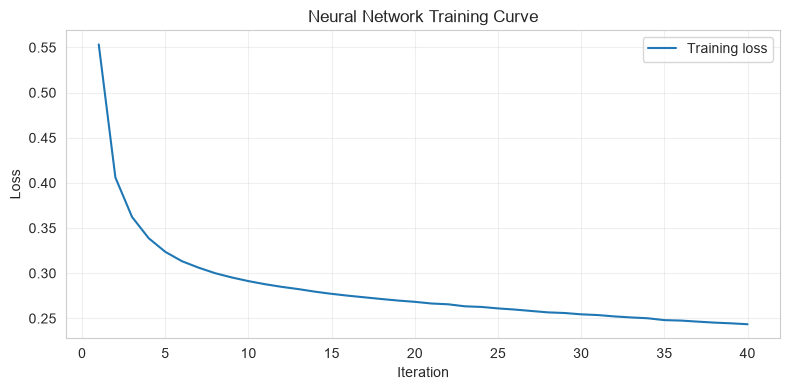

Neural network training curve saved successfully.
File: outputs/fig12_nn_training.png


In [62]:
# MLPClassifier stores loss values during training
loss_values = mlp.named_steps["model"].loss_curve_

plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(loss_values) + 1),
    loss_values,
    label="Training loss"
)

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Neural Network Training Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "outputs/fig12_nn_training.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Neural network training curve saved successfully.")
print("File: outputs/fig12_nn_training.png")

In [63]:
# Overall conversion rate
overall = df_clean["Conversion"].mean()

# Conversion rate by channel
channel_rate = (
    df_clean.groupby("CampaignChannel")["Conversion"]
    .mean()
    .sort_values(ascending=False)
)

# Conversion rate by campaign type
type_rate = (
    df_clean.groupby("CampaignType")["Conversion"]
    .mean()
    .sort_values(ascending=False)
)

# Top 5 model features
top_feats = ", ".join(
    imp_grouped["Feature"].head(5)
)

# Final XGBoost metrics
f1m = final_metrics.loc[
    final_metrics["Metric"] == "F1 Macro", "Score"
].iloc[0]

roc = final_metrics.loc[
    final_metrics["Metric"] == "ROC-AUC", "Score"
].iloc[0]

# Verified facts only
facts = [
    f"Overall conversion rate is {overall:.1%}.",
    f"Best channel: {channel_rate.index[0]} at {channel_rate.iloc[0]:.1%}; "
    f"weakest: {channel_rate.index[-1]} at {channel_rate.iloc[-1]:.1%}.",
    f"Best campaign type: {type_rate.index[0]} at {type_rate.iloc[0]:.1%}; "
    f"weakest: {type_rate.index[-1]} at {type_rate.iloc[-1]:.1%}.",
    f"The most important features in the model are: {top_feats}.",
    f"The final model (XGBoost) reaches macro F1 {f1m:.2f} "
    f"and ROC-AUC {roc:.2f} on unseen customers."
]

prompt = (
    "You are a marketing analyst. Using only the facts below, write: "
    "1) a five-sentence executive summary, "
    "2) three practical campaign recommendations, "
    "3) one caution about what this analysis cannot prove. "
    "Do not invent any numbers."
    + "\n\n"
    + "\n".join("- " + s for s in facts)
)

with open("outputs/llm_prompt.txt", "w", encoding="utf-8") as f:
    f.write(prompt)

print("GENAI PROMPT")
print("=" * 60)
print(prompt)

print("\nSaved:")
print("outputs/llm_prompt.txt")

GENAI PROMPT
You are a marketing analyst. Using only the facts below, write: 1) a five-sentence executive summary, 2) three practical campaign recommendations, 3) one caution about what this analysis cannot prove. Do not invent any numbers.

- Overall conversion rate is 87.6%.
- Best channel: Referral at 88.3%; weakest: Social Media at 86.8%.
- Best campaign type: Conversion at 93.4%; weakest: Awareness at 85.6%.
- The most important features in the model are: CampaignType, PreviousPurchases, CampaignChannel, EmailClicks, EmailOpens.
- The final model (XGBoost) reaches macro F1 0.76 and ROC-AUC 0.82 on unseen customers.

Saved:
outputs/llm_prompt.txt


In [64]:
import joblib

# Save the complete pipeline
joblib.dump(
    final_model,
    "models/conversion_model.pkl"
)

print("Final model saved successfully.")
print("File: models/conversion_model.pkl")

# Reload the saved model
loaded_model = joblib.load(
    "models/conversion_model.pkl"
)

# Test the reloaded model on one customer
one_customer = X_test.iloc[[0]]

print("\nTEST CUSTOMER")
print("=" * 60)
print(one_customer.T)

print(
    "\nPredicted class:",
    loaded_model.predict(one_customer)[0]
)

print(
    "Probability of converting:",
    round(
        loaded_model.predict_proba(one_customer)[0, 1],
        3
    )
)

print(
    "Actual outcome:",
    y_test.iloc[0]
)

Final model saved successfully.
File: models/conversion_model.pkl

TEST CUSTOMER
                          3344
Age                         43
Gender                  Female
Income                   30558
CampaignChannel          Email
CampaignType        Conversion
AdSpend            2076.535114
ClickThroughRate      0.077155
ConversionRate        0.015477
WebsiteVisits                9
PagesPerVisit         7.818845
TimeOnSite           14.229982
SocialShares                83
EmailOpens                  11
EmailClicks                  4
PreviousPurchases            2
LoyaltyPoints              951
EmailClickRate        0.333333
SpendPerVisit       207.653511

Predicted class: 1
Probability of converting: 0.945
Actual outcome: 1


In [65]:
import os
import sklearn

print("MODEL FILE CHECK")
print("=" * 60)

print(
    "Model file exists:",
    os.path.exists("models/conversion_model.pkl")
)

print(
    "Model file size (KB):",
    round(
        os.path.getsize("models/conversion_model.pkl") / 1024,
        1
    )
)

print(
    "scikit-learn version:",
    sklearn.__version__
)

print("\nPrediction consistency check:")

original_predictions = final_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

print(
    "Same predictions:",
    (original_predictions == loaded_predictions).all()
)

MODEL FILE CHECK
Model file exists: True
Model file size (KB): 235.6
scikit-learn version: 1.9.1

Prediction consistency check:
Same predictions: True


In [67]:
# ==========================================
# CELL 66 — POWER BI DASHBOARD DATA
# ==========================================

from sklearn.metrics import confusion_matrix
import os
import joblib

# --------------------------------------------------
# 0. LOAD FINAL MODEL IF NEEDED
# --------------------------------------------------

if "final_model" not in globals():
    final_model = joblib.load("models/conversion_model.pkl")
    print("Final model loaded from models/conversion_model.pkl")
else:
    print("Final model already available in notebook memory.")


# --------------------------------------------------
# 1. CREATE FINAL MODEL PREDICTIONS
# --------------------------------------------------

pred_final = final_model.predict(X_test)
prob_final = final_model.predict_proba(X_test)[:, 1]

print("\nFinal model predictions created.")
print("Test predictions:", len(pred_final))


# --------------------------------------------------
# 2. ALL CUSTOMERS
# Used for conversion-pattern analysis
# --------------------------------------------------

all_customers = df_clean.copy()

# Readable conversion labels
all_customers["ConversionLabel"] = (
    all_customers["Conversion"]
    .map({
        1: "Converted",
        0: "Not converted"
    })
)

# Age groups
all_customers["AgeBand"] = pd.cut(
    all_customers["Age"],
    bins=[0, 24, 34, 44, 54, 120],
    labels=[
        "18-24",
        "25-34",
        "35-44",
        "45-54",
        "55+"
    ]
)

# Income quartiles
all_customers["IncomeBand"] = pd.qcut(
    all_customers["Income"],
    4,
    labels=[
        "Q1 lowest",
        "Q2",
        "Q3",
        "Q4 highest"
    ],
    duplicates="drop"
)

# Save all customers
all_customers.to_csv(
    "outputs/dashboard_all_customers.csv",
    index=False
)


# --------------------------------------------------
# 3. TEST CUSTOMERS + MODEL PREDICTIONS
# --------------------------------------------------

test_predictions = X_test.copy()

test_predictions["Actual"] = y_test.values

test_predictions["PredictedClass"] = pred_final

test_predictions["PredictedProbability"] = (
    prob_final.round(4)
)

test_predictions["Correct"] = (
    test_predictions["Actual"]
    == test_predictions["PredictedClass"]
).astype(int)

test_predictions.to_csv(
    "outputs/dashboard_test_predictions.csv",
    index=False
)


# --------------------------------------------------
# 4. CONFUSION MATRIX
# --------------------------------------------------

cm = confusion_matrix(
    y_test,
    pred_final
)

cm_table = pd.DataFrame({
    "Actual": [
        "Not converted",
        "Not converted",
        "Converted",
        "Converted"
    ],

    "Predicted": [
        "Not converted",
        "Converted",
        "Not converted",
        "Converted"
    ],

    "Customers": [
        cm[0, 0],
        cm[0, 1],
        cm[1, 0],
        cm[1, 1]
    ]
})

cm_table.to_csv(
    "outputs/dashboard_confusion_matrix.csv",
    index=False
)


# --------------------------------------------------
# 5. FINAL CHECK
# --------------------------------------------------

print("\n" + "=" * 60)
print("POWER BI DASHBOARD DATA READY")
print("=" * 60)

print("\nDashboard files:")

files_to_check = [
    "dashboard_all_customers.csv",
    "dashboard_test_predictions.csv",
    "dashboard_confusion_matrix.csv",
    "model_comparison.csv",
    "final_model_metrics.csv",
    "feature_importance.csv"
]

for file in files_to_check:
    exists = os.path.exists("outputs/" + file)
    print(file, "->", exists)

print("\nTest rows:", len(test_predictions))

print("\nConfusion Matrix:")
print(cm_table)

print("\nConfusion matrix total:",
      cm_table["Customers"].sum())

Final model already available in notebook memory.

Final model predictions created.
Test predictions: 1600

POWER BI DASHBOARD DATA READY

Dashboard files:
dashboard_all_customers.csv -> True
dashboard_test_predictions.csv -> True
dashboard_confusion_matrix.csv -> True
model_comparison.csv -> True
final_model_metrics.csv -> True
feature_importance.csv -> True

Test rows: 1600

Confusion Matrix:
          Actual      Predicted  Customers
0  Not converted  Not converted         83
1  Not converted      Converted        115
2      Converted  Not converted         10
3      Converted      Converted       1392

Confusion matrix total: 1600
